In [ ]:
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import numpy as np

from IPython.core.magic import register_cell_magic
@register_cell_magic
def skip(line, cell):
    return

### 1. CONFIGURATION: Dataset selection

In [ ]:
# Define analysis scope: SWW/GroupE datasets, building types, categorical features

main_path = "/Users/jansigrist/Documents/SP/Customer_Segmentation_Lantern" # adjust to user environment
clustering_method = 'KMed' # Options: 'kProt', 'kMed', 'kMeans'
dataset = 'SWW'  # Options: 'SWW', 'GroupE'
building_type = 'flat'  # Options: 'flat', 'house'
categorical_features = 'sociodemographic'  # Options: 'technical', 'sociodemographic'

### 2. SURVEY DATA: Load sociodemographic/technical features from Excel

In [ ]:
# Dataset-specific column extraction due to varying survey structures

data_type = (f'hourly_avg_clustering_{clustering_method}_{building_type}_{categorical_features}')

# Load the Excel file with survey data
file_path = (f"{main_path}/DATA/{dataset}/Survey_Data/Survey_Data_{dataset}.xlsx")

# Define columns to extract based on dataset
if dataset == "SWW":
    df = pd.read_excel(file_path, skiprows=4, nrows=1500, header=None,dtype={10: str})
    cols_to_extract = [10, 142, 143, 144, 145, 146, 147, 148, 149, 150, 152, 154, 127, 129, 155, 131, 128, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165]
elif dataset == "GroupE":
    df = pd.read_excel(file_path, skiprows=3, nrows=1500, header=None,dtype={0: str})
    cols_to_extract = [0, 148, 149, 150, 151, 152, 153, 154, 155, 156, 158, 160, 134, 136, 161, 138, 135, 162, 163, 154, 155, 166, 167, 168, 169, 170, 171]
extracted_df = df.iloc[:, cols_to_extract]

# Rename columns for clarity
extracted_df.columns = ['resident_id', 'Building Type', 'Heating', 'Water Heating', 
                        'Solar Panels', 'Electric Vehicle', 'Heat Pump', 'Individual Electric Boiler', 
                        'Individual Washing Machine', 'Home Battery','Number of Residents',
                        'Number of Days at Home','Age','Education', 'Employment', 'Tenant Type',
                        'Income','DR scenario', 'DR heating', 'DR hot water', 'DR EV', 'DR appliances', 
                        'Control Technologies','Optimal Usage Time', 'Automated DR', 'Emergency DR', 'LEC']

extracted_df_pl = pl.from_pandas(extracted_df)

# Check for duplicates in resident_id
total_rows = extracted_df_pl.height
unique_resident_ids = extracted_df_pl["resident_id"].n_unique()

print(f"Total rows: {total_rows}")
print(f"Unique resident_id count: {unique_resident_ids}")

if total_rows > unique_resident_ids:
    print(f"There are {total_rows - unique_resident_ids} duplicate resident_id entries.")
else:
    print("No duplicates found in resident_id column.")

Total rows: 1500
Unique resident_id count: 1500
No duplicates found in resident_id column.


### 3. STATISTICS: Generate cluster summary statistics

In [ ]:
# Read the clustering results file and assign household statistics

# Read the clustering results file
result_df = pl.read_csv(f"{main_path}/Results/{dataset}/DATA/Cluster/{data_type}.csv")

# Read the dataset_summary_statistics file
dataset_summary_stats_df = pl.read_csv(f"{main_path}/DATA/{dataset}/dataset_summary_stats.csv") 

# Standardize resident_id/file_id columns for accurate merging
result_df = result_df.with_columns(
    pl.col("resident_id")
      .cast(pl.Utf8)
      .str.strip_chars()
      .str.to_lowercase()
      .alias("resident_id")
)

dataset_summary_stats_df = dataset_summary_stats_df.with_columns(
    pl.col("file_id")
      .cast(pl.Utf8)
      .str.strip_chars()
      .str.to_lowercase()
      .alias("resident_id")
)

result_df = result_df.join(
    dataset_summary_stats_df.select([
        "resident_id",
        "bruttolastgang_kwh_sum",
        "average_daily_consumption"
    ]),
    on="resident_id",
    how="left"
)
result_df = result_df.select([
    "resident_id",
    "cluster",
    "bruttolastgang_kwh_sum",
    "average_daily_consumption"  
])

cluster_summary = result_df.group_by("cluster").agg([
    pl.count("resident_id").alias("num_households"),
    pl.mean("bruttolastgang_kwh_sum").alias("avg_total_consumption [kWh]").round(2),
    pl.mean("average_daily_consumption").alias("avg_daily_consumption [kWh]").round(2)
]).sort("cluster")

print(cluster_summary)

shape: (3, 4)
┌─────────┬────────────────┬─────────────────────────────┬─────────────────────────────┐
│ cluster ┆ num_households ┆ avg_total_consumption [kWh] ┆ avg_daily_consumption [kWh] │
│ ---     ┆ ---            ┆ ---                         ┆ ---                         │
│ i64     ┆ u32            ┆ f64                         ┆ f64                         │
╞═════════╪════════════════╪═════════════════════════════╪═════════════════════════════╡
│ 1       ┆ 368            ┆ 1852.06                     ┆ 5.05                        │
│ 2       ┆ 140            ┆ 1985.67                     ┆ 5.41                        │
│ 3       ┆ 293            ┆ 1807.03                     ┆ 4.92                        │
└─────────┴────────────────┴─────────────────────────────┴─────────────────────────────┘


In [ ]:
# Build final DataFrame with survey and consumption data

extracted_pl_df = pl.from_pandas(extracted_df)
print(extracted_pl_df.shape)

# Read the dataset_summary_stats file
dataset_summary_stats_df = pl.read_csv(f"{main_path}/DATA/{dataset}/dataset_summary_stats.csv")

# Standardize keys in all DataFrames for clean join
result_df = result_df.with_columns(
    pl.col("resident_id")
      .cast(pl.Utf8)
      .str.strip_chars()
      .str.to_lowercase()
      .alias("resident_id")
)

extracted_pl_df = extracted_pl_df.with_columns(
    pl.col("resident_id")
      .cast(pl.Utf8)
      .str.strip_chars()
      .str.to_lowercase()
      .alias("resident_id")
)

dataset_summary_stats_df = dataset_summary_stats_df.with_columns(
    pl.col("file_id")
      .cast(pl.Utf8)
      .str.strip_chars()
      .str.to_lowercase()
      .alias("resident_id")
)

# First join: attach survey columns
joined = result_df.join(
    extracted_pl_df.select([
    "resident_id",
    "Building Type",
    "Heating",
    "Water Heating",
    "Heat Pump",
    "Solar Panels",
    "Electric Vehicle",
    'Home Battery',
    'Individual Electric Boiler',
    'Individual Washing Machine',
    'Number of Residents',
    'Number of Days at Home',
    'Age',
    'Education',
    'Employment',
    "Tenant Type",
    "Income",
    "DR scenario",
    "DR heating",
    "DR hot water",
    "DR EV",
    "DR appliances",
    'Control Technologies',
    'Optimal Usage Time',
    'Automated DR',
    'Emergency DR',
    'LEC'
    ]),
    on="resident_id",
    how="left"
)

# Second join: attach consumption
joined = joined.join(
    dataset_summary_stats_df.select(["resident_id", "bruttolastgang_kwh_sum"]),
    on="resident_id",
    how="left"
)

# Define the order of columns for the final DataFrame
final_df = joined.select([
    "resident_id",                
    "bruttolastgang_kwh_sum",  
    "cluster",                 
    "Building Type",
    "Heating",
    "Water Heating",
    "Heat Pump",
    "Solar Panels",
    "Electric Vehicle",
    'Home Battery',
    'Individual Electric Boiler',
    'Individual Washing Machine',
    'Number of Residents',
    'Number of Days at Home',
    'Age',
    'Education',
    'Employment',
    "Tenant Type",
    "Income",
    "DR scenario",
    "DR heating",
    "DR hot water",
    "DR EV",
    "DR appliances",
    'Control Technologies',
    'Optimal Usage Time',
    'Automated DR',
    'Emergency DR',
    'LEC'
])

(1500, 27)


In [ ]:
# Categorize consumption into bins

def categorize_consumption(value):
    
    if value < 5000:
        return "0-5 MWh"
    elif value < 10000:
        return "5-10 MWh"
    elif value < 15000:
        return "10-15 MWh"
    elif value < 20000:
        return "15-20 MWh"
    elif value < 25000:
        return "20-25 MWh"
    else:
        return "25+ MWh"

final_df = final_df.with_columns(
    pl.col("bruttolastgang_kwh_sum")
      .map_elements(categorize_consumption, return_dtype=pl.Utf8)
      .alias("consumption_category")
)

print(final_df)

# Save the final DataFrame to CSV
final_df.write_csv(f"{main_path}/Results/{dataset}/DATA/Survey/hourly_avg_clustering_category_{data_type}.csv")


shape: (801, 30)
┌────────────┬───────────┬─────────┬───────────┬───┬───────────┬───────────┬───────────┬───────────┐
│ resident_i ┆ bruttolas ┆ cluster ┆ Building  ┆ … ┆ Automated ┆ Emergency ┆ LEC       ┆ consumpti │
│ d          ┆ tgang_kwh ┆ ---     ┆ Type      ┆   ┆ DR        ┆ DR        ┆ ---       ┆ on_catego │
│ ---        ┆ _sum      ┆ i64     ┆ ---       ┆   ┆ ---       ┆ ---       ┆ str       ┆ ry        │
│ str        ┆ ---       ┆         ┆ str       ┆   ┆ str       ┆ str       ┆           ┆ ---       │
│            ┆ f64       ┆         ┆           ┆   ┆           ┆           ┆           ┆ str       │
╞════════════╪═══════════╪═════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪═══════════╡
│ 12850      ┆ 3573.144  ┆ 1       ┆ Flat      ┆ … ┆ + +       ┆ No Inform ┆ No Inform ┆ 0-5 MWh   │
│            ┆           ┆         ┆           ┆   ┆           ┆ ation     ┆ ation     ┆           │
│ 37408      ┆ 2494.5    ┆ 1       ┆ Flat      ┆ … ┆ /         ┆ No Inform

In [ ]:
%%skip

# Outlier Analysis to identify high consumption households with EVs

count = final_df.filter(
    (pl.col('bruttolastgang_kwh_sum') > 30000) &
    (pl.col('Electric Vehicle') == 'yes')
).height

print(count)

count = final_df.filter(
    (pl.col('bruttolastgang_kwh_sum') > 30000)
).height

print(f"Total households with consumption > 30,000 kWh: {count}")

### 4. RESULT VISUALIZATION: Generate plots to show distribution of Demand Response Indicators, Technical assets, and Sociodemographics

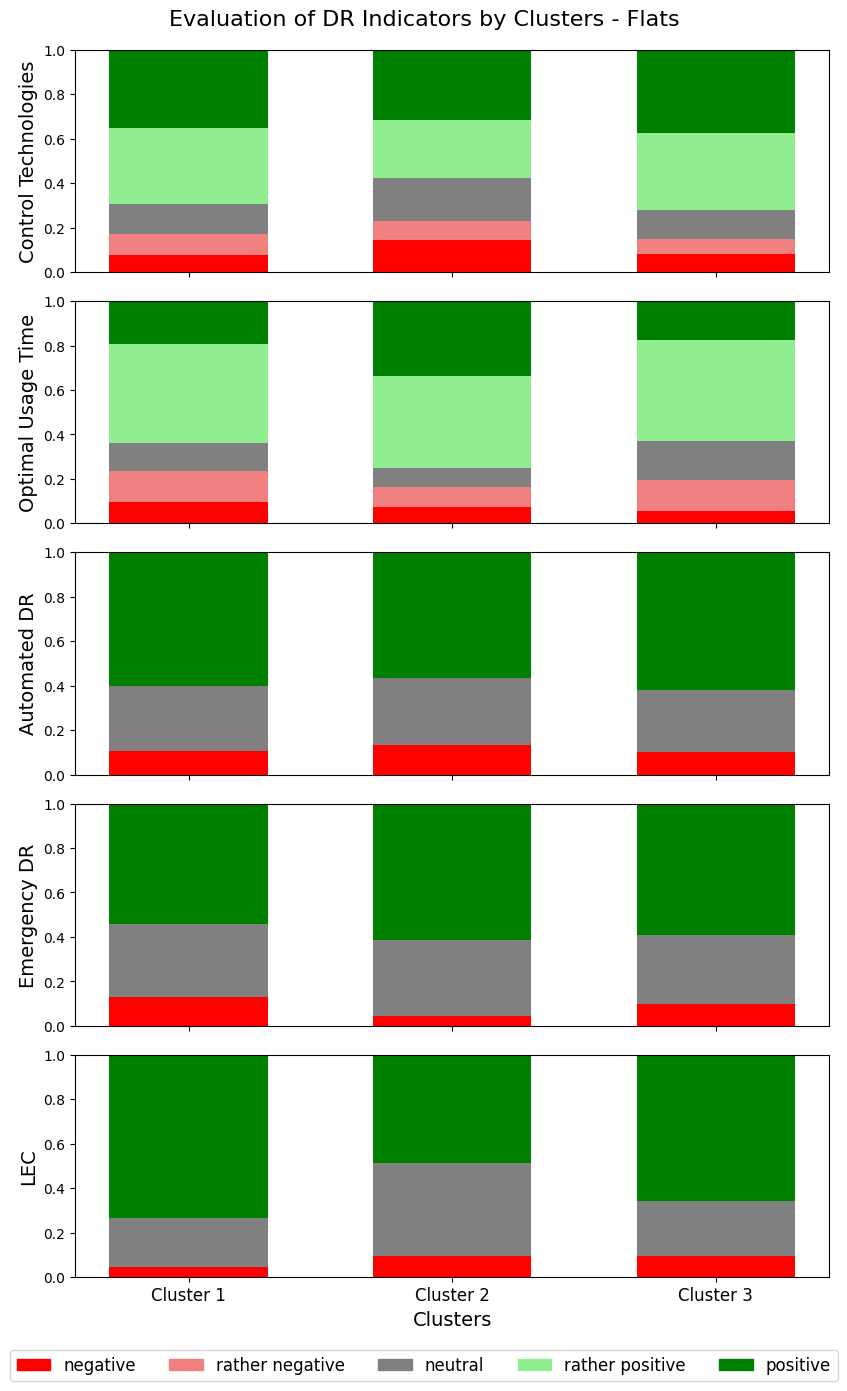

In [ ]:
# DR Indicators Analysis and Plotting

# Define DR-related columns and their categories
dr_columns = ['Control Technologies', 'Optimal Usage Time', 'Automated DR', 'Emergency DR', 'LEC']
dr_category_order = ['- -','-', '/', '+','+ +']
dr_category_colors = {'- -':'red','-':'lightcoral', '/': 'grey', '+': 'lightgreen','+ +': 'green'}

dr_legend = ['negative', 'rather negative', 'neutral', 'rather positive', 'positive']

clusters = final_df['cluster'].unique()
n_clusters = len(clusters)
n_dr = len(dr_columns)
bar_width = 0.18
intra_cluster_gap = 0.12

bar_data = np.zeros((n_clusters, n_dr, len(dr_category_order)))
for cluster_idx, cl in enumerate(clusters):
    cluster_subset = final_df.filter(pl.col('cluster') == cl)
    for dr_idx, col in enumerate(dr_columns):
        answers = cluster_subset[col]
        valid_answers = answers.filter(~(answers == "No Information"))
        total = len(valid_answers)
        category_counts = [(valid_answers == cat).sum() for cat in dr_category_order]
        fracs = [count / total if total > 0 else 0 for count in category_counts]
        bar_data[cluster_idx, dr_idx, :] = fracs

fig, axs = plt.subplots(n_dr, 1, figsize=(6 + n_clusters*0.8, n_dr*3), sharex=True)

if n_dr == 1:
    axs = [axs]

cluster_positions = np.arange(n_clusters) * (bar_width + intra_cluster_gap)
bar_middle_positions = cluster_positions

for dr_idx, ax in enumerate(axs):
    bottom = np.zeros(n_clusters)
    for cat_idx, cat in enumerate(dr_category_order):
        values = bar_data[:, dr_idx, cat_idx]
        ax.bar(cluster_positions, values, bottom=bottom, width=bar_width, color=dr_category_colors[cat],
               label=cat if dr_idx == 0 else "")
        bottom += values

    ax.set_ylim(0, 1)
    ax.set_ylabel(dr_columns[dr_idx], fontsize=14)
    ax.grid(False, axis='y')

axs[-1].set_xticks(bar_middle_positions)
axs[-1].set_xticklabels([f'Cluster {cl}' for cl in clusters], rotation=0, ha='center', fontsize=12)
axs[-1].set_xlabel('Clusters', fontsize=14)

fig.suptitle(f'Evaluation of DR Indicators by Clusters - {building_type.capitalize()}s', fontsize=16, y=0.94)

handles = [plt.Rectangle((0,0),1,1,color=dr_category_colors[cat]) for cat in dr_category_order]
labels = dr_legend
fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, +0.02), ncol=len(dr_category_order), fontsize='large')

plt.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.savefig(f"{main_path}/Results/{dataset}/Plots/Survey/DR_{data_type}.png")
plt.show()

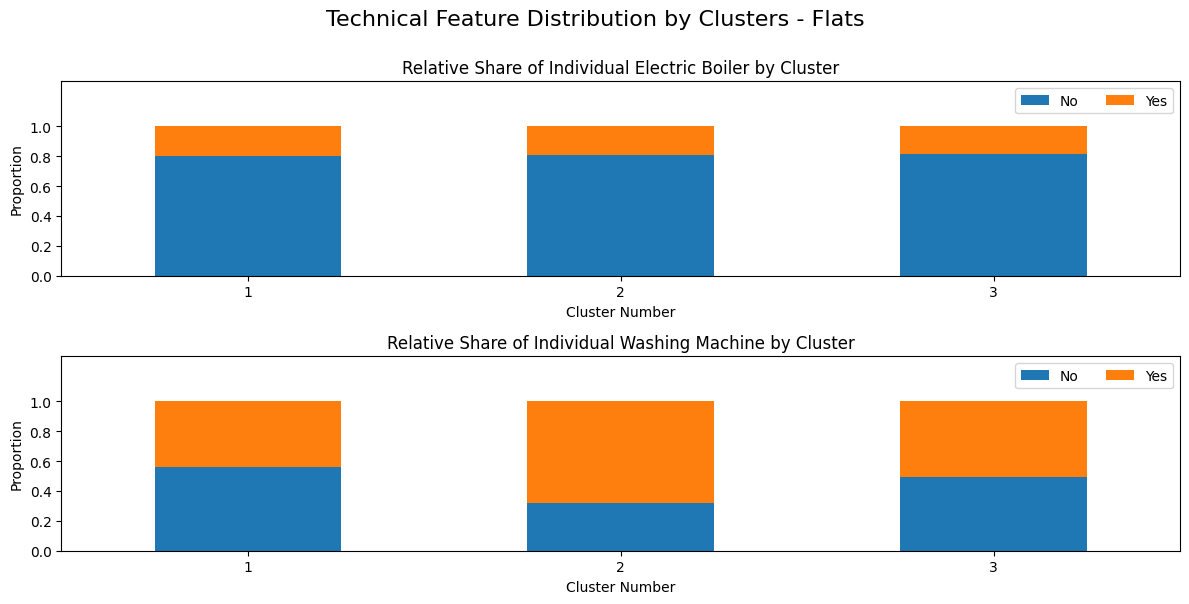

In [ ]:
# Plot technical feature distribution by clusters

custom_category_orders = {
    'Solar Panels': ['No', 'Yes'],
    'Electric Vehicle': ['No', 'Yes'],
    'Water Heating': ['Other', 'Boiler', 'Heat Pump'],
    'Heating': ['Other', 'Boiler', 'Heat Pump'],
    'Home Battery': ['No', 'Yes'],
    'Individual Electric Boiler': ['No', 'Yes'],
    'Individual Washing Machine': ['No', 'Yes'],
}

# Select features based on building type
if building_type == 'flat':
    category_features = ['Individual Electric Boiler', 'Individual Washing Machine']
else:
    category_features = ['Heating', 'Water Heating', 'Solar Panels', 'Home Battery', 'Electric Vehicle']

n_features = len(category_features)

final_df_plot = final_df.to_pandas()

fig, axes = plt.subplots(n_features, 1, figsize=(12, 3 * n_features))

if n_features == 1:
    axes = [axes]

for i, feature in enumerate(category_features):
    ax = axes[i]
    counts = final_df_plot.groupby(['cluster', feature]).size().unstack(fill_value=0)
    proportions = counts.div(counts.sum(axis=1), axis=0)
    
    # Apply custom category order
    order = custom_category_orders[feature]
    proportions = proportions.reindex(columns=order)
    proportions.plot(kind='bar', stacked=True, ax=ax)
    
    ax.set_title(f'Relative Share of {feature.title()} by Cluster')
    ax.set_ylabel('Proportion')
    ax.set_xlabel('Cluster Number')
    ax.set_ylim(0, 1.3)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
    ax.legend(
        loc='upper right',
        bbox_to_anchor=(1, 1),
        ncol=len(order),
        fontsize='medium'
    )
    #display(proportions.round(3))
plt.suptitle(f'Technical Feature Distribution by Clusters - {building_type.capitalize()}s', fontsize=16, y=1.00)
plt.tight_layout()
plt.savefig(
f"{main_path}/Results/{dataset}/Plots/Survey/{data_type}_technicalResults.png"
)
plt.show()

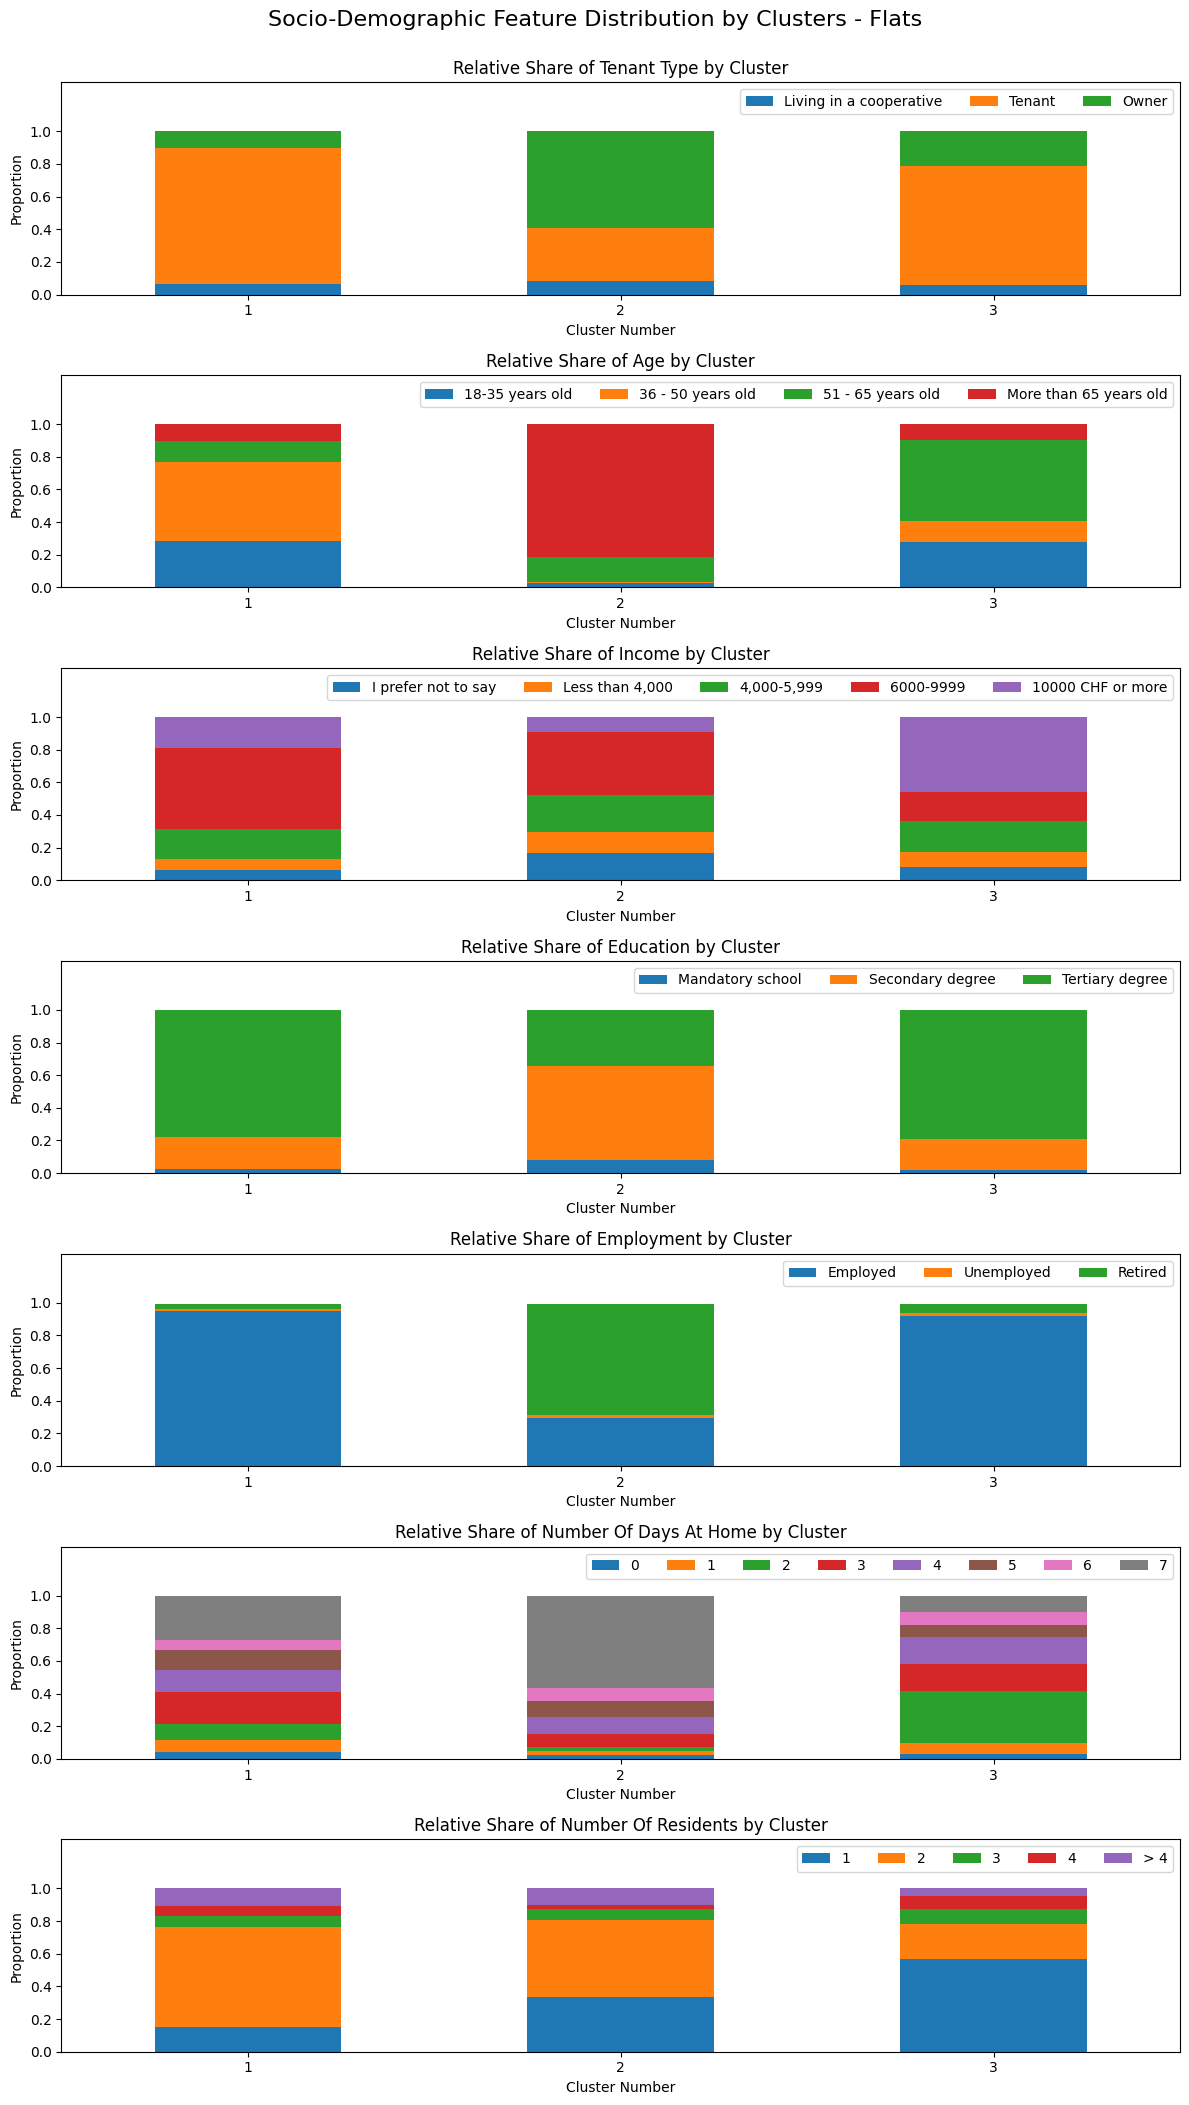

In [ ]:
# Plot sociodemographic feature distribution by clusters

# Rename education levels for clarity
old_to_new_education = {
    'Mandatory school': 'Mandatory school',
    'Secondary degree (Apprenticeship, high school et commercial/general culture school)': 'Secondary degree',
    'Tertiary degree  (Superior school (ES), University/EPF, vocational university)': 'Tertiary degree',
}

# Define custom category orders for plotting
custom_category_orders = {
    'Tenant Type': ['Living in a cooperative', 'Tenant', 'Owner'],
    'Age': ['18-35 years old', '36 - 50 years old', '51 - 65 years old', 'More than 65 years old'],
    'Income': ['I prefer not to say', 'Less than 4,000', '4,000-5,999','6000-9999','10000 CHF or more' ],
    'Education': ['Mandatory school', 'Secondary degree', 'Tertiary degree'],
    'Employment': ['Employed', 'Unemployed', 'Retired'],
    'Number of Residents':['1', '2', '3', '4', '> 4'],
    'Number of Days at Home': ['0', '1', '2', '3', '4', '5', '6', '7']
}

category_features = ['Tenant Type', 'Age', 'Income', 'Education', 'Employment', 'Number of Days at Home', 'Number of Residents']
n_features = len(category_features)

final_df_plot = final_df.to_pandas()

# Apply education level renaming
final_df_plot["Education"] = final_df_plot["Education"].replace(old_to_new_education)

fig, axes = plt.subplots(n_features, 1, figsize=(12, 3 * n_features))

if n_features == 1:
    axes = [axes]

for i, feature in enumerate(category_features):
    ax = axes[i]
    counts = final_df_plot.groupby(['cluster', feature]).size().unstack(fill_value=0)
    proportions = counts.div(counts.sum(axis=1), axis=0)
    
    # Apply custom category order
    order = custom_category_orders[feature]
    proportions = proportions.reindex(columns=order)
    proportions.plot(kind='bar', stacked=True, ax=ax)
    
    ax.set_title(f'Relative Share of {feature.title()} by Cluster')
    ax.set_ylabel('Proportion')
    ax.set_xlabel('Cluster Number')
    ax.set_ylim(0, 1.3)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
    ax.legend(
        loc='upper right',
        bbox_to_anchor=(1, 1),
        ncol=8,
        fontsize='medium'
    )
    #display(proportions.round(3))
plt.suptitle(f'Socio-Demographic Feature Distribution by Clusters - {building_type.capitalize()}s', fontsize=16, y=1.00)
plt.tight_layout()
plt.savefig(
f"{main_path}/Results/{dataset}/Plots/Survey/{data_type}_sociodemographicResults.png"
)
plt.show()